In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import lpmv, gammaln
from scipy.special import ive

Gaussian on a sphere: We want to freeze all angles except for one angle and see if the log of the likelihood look like the m-2 function of that angle. To do so, we will freeze everything except one angle, plot of 0 to 2pi the log of probability, and describe the simple 2d function as a sum of seperable functions. 

Generating the random 3d Gaussian evaluated on the unit sphere. Fixing the seed so code is reproducable. Selecting mean as a random point in 3d space. If mean is at the origin the linear term vanishes and the quadratic shape matters, if mean is far the linear term dominates, if the mean is around 2 both terms compete. Sig set to guarantee a valid covariance, since it is automatically symmetric and positive semi-definite. P is the precision matrix. 

In [11]:
rng = np.random.default_rng(0)
mu = rng.normal(size=3) * 2
A = rng.normal(size=(3, 3)); Sig = A @ A.T + 0.3*np.eye(3)
P = np.linalg.inv(Sig)

# The log likelihood up to an additive constant
def logf(x):
    d = x - mu
    return -0.5 * np.einsum('...i,ij,...j->...', d, P, d)

# Spherical to cartesian
def unit(t, p):
    t, p = np.broadcast_arrays(t, p)
    return np.stack([np.sin(t)*np.cos(p), np.sin(t)*np.sin(p), np.cos(t)], -1)

# Freezing all angles but 1, sampling from 0 to 2pi
N = 64
s = 2*np.pi*np.arange(N)/N
t0 = 0.9; L_phi = logf(unit(t0, s)) # phi sweeps a small cicle at theta=0.9
p0 = 0.4; L_th = logf(unit(s, p0)) # theta sweeps the full circle from 0 to 2pi through both poles

def spec(L):
    return np.abs(np.fft.rfft(L) / len(L))

for name, L in [("phi sweep", L_phi), ("theta sweep", L_th)]:
    a = spec(L)
    print(name, a[:7], "max |c_m| for m>2:", a[3:].max())

print(spec(np.exp(L_phi - L_phi.max()))[:9])

fine = np.linspace(0, 2*np.pi, 1000, endpoint=False)
s5 = 2*np.pi*np.arange(5)/5
c5 = np.fft.fft(logf(unit(t0, s5))) / 5
m = np.array([0, 1, 2, -2, -1])
recon = np.real(sum(c5[k]*np.exp(1j*m[k]*fine) for k in range(5)))
print("max reconstruction error:", np.abs(recon - logf(unit(t0, fine))).max())

th = np.linspace(0, np.pi, 200)
ph = np.linspace(0, 2*np.pi, 300, endpoint=False)
G = logf(unit(th[:, None], ph[None, :]))
print("singular values of log f:", np.linalg.svd(G, compute_uv=False)[:8])
print("singular values of f:", np.linalg.svd(np.exp(G - G.max()), compute_uv=False)[:10])

phi sweep [7.00006742e-01 3.14883307e-01 1.11190226e-01 3.18433658e-17
 2.58843579e-17 2.01310610e-17 3.43865644e-17] max |c_m| for m>2: 6.206335383118183e-17
theta sweep [1.90218487e+00 1.04397269e+00 2.26646739e-01 6.52555413e-17
 4.06570473e-17 3.89596421e-17 6.80150727e-17] max |c_m| for m>2: 1.6514237996341835e-16
[6.45286229e-01 1.75787416e-01 4.59215949e-02 1.76651734e-02
 1.62026907e-03 8.58786951e-04 5.67927239e-05 2.74808589e-05
 2.13776126e-06]
max reconstruction error: 8.881784197001252e-16
singular values of log f: [5.39800987e+02 9.56481292e+01 1.66936349e+01 4.51408141e+00
 4.40368050e-13 4.33316491e-13 3.93434083e-13 3.30003838e-13]
singular values of f: [1.22183088e+02 2.69273856e+01 6.31350803e+00 1.74648232e+00
 5.79864495e-01 2.94535356e-01 7.25711938e-02 3.79790609e-02
 7.79073924e-03 3.11029551e-03]


max error: 8.326672684688674e-16


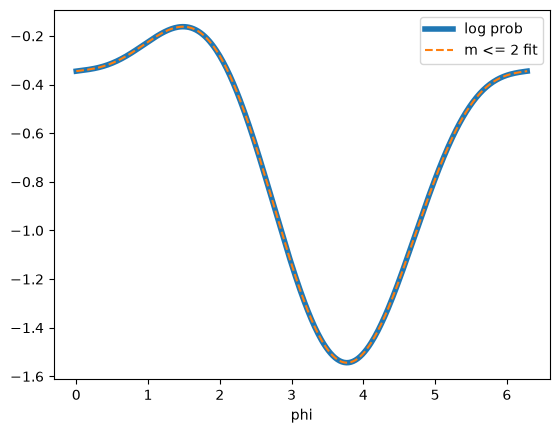

In [13]:
phi = np.linspace(0, 2*np.pi, 400)
y = logf(unit(0.9, phi)) # freezing theta at 0.9 and sweeping phi

basis = np.column_stack([np.ones_like(phi), np.cos(phi), np.sin(phi), np.cos(2*phi), np.sin(2*phi)])
coef, *_ = np.linalg.lstsq(basis, y, rcond=None)
print("max error:", np.max(np.abs(basis @ coef - y)))

plt.plot(phi, y, lw=4, label="log prob")
plt.plot(phi, basis @ coef, "--", label="m <= 2 fit")
plt.xlabel("phi"); plt.legend(); plt.show()

In this plot, we fix theta at 0.9, and evalute phi from 0 to 2pi. The height of the curve at each point denotes the log of that probability--higher means more likely and vice versa. The solid line is the actual probability and the dashed line is the probability we obtain by adding together 5 waves: a flat constant, cosphi, sinphi, cos2phi, and sin2phi. Notice that theres is no error between our approximation and the actual log probability so we can conclude that the lof probability around the ring is made up of maximum m = 2 waves. 

We are showing how our Fourier and spherical harmonic approximations in GAEL are exact. For nuisance angles in real exoplanet likelihoods that only depend on rotation we can apply this model to predict likelihoods, however for angles that are not rotation-only dependent this prediction fails. 

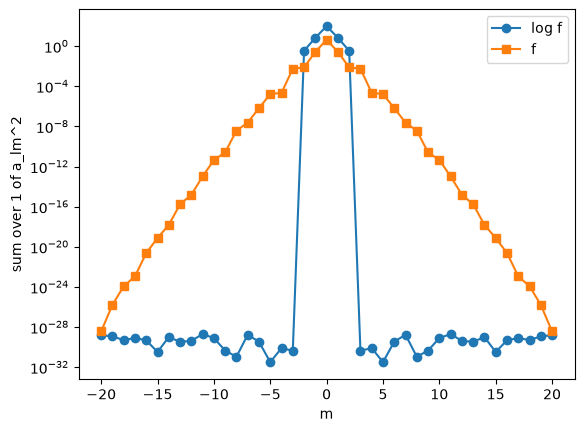

(<matplotlib.legend.Legend at 0x12c49acf0>, None)

In [22]:
# Defining the real spherical harmonics
def real_Y(l, m, t, p):
    am = abs(m)
    N = np.sqrt((2*l+1)/(4*np.pi) * np.exp(gammaln(l-am+1) - gammaln(l+am+1)))
    Plm = lpmv(am, l, np.cos(t)) * (-1)**am
    if m == 0: return np.sqrt(2)*N*Plm*np.cos(am*p)
    return np.sqrt(2)*N*Plm*np.sin(am*p)

# Gauss-legendre quadrature in cos(theta)
Lmax = 20
xg, wg = np.polynomial.legendre.leggauss(31)
th = np.arccos(xg); ph = 2*np.pi*np.arange(61)/61
T, Ph = np.meshgrid(th, ph, indexing="ij")
W = wg[:, None] * (2*np.pi/61)

Ys = {(l, m): real_Y(l, m, T, Ph) for l in range(Lmax+1) for m in range(-l, l+1)}

def power_per_m(F):
    a = {k: np.sum(W*F*Y) for k, Y in Ys.items()}
    return np.array([sum(a[(l, m)]**2 for l in range(abs(m), Lmax+1))
                    for m in range(-Lmax, Lmax+1)])

F1 = logf(unit(T, Ph))
Ff = np.exp(F1 - F1.max())

ms = np.arange(-Lmax, Lmax+1)
plt.semilogy(ms, power_per_m(F1) + 1e-32, "o-", label='log f')
plt.semilogy(ms, power_per_m(Ff) + 1e-32, "s-", label="f")
plt.xlabel("m"); plt.ylabel("sum over 1 of a_lm^2"); plt.legend(), plt.show()

The log of a Gaussian is a polynomial of degree 2 in x,y, and z, and thus it can be expressed as a combination of spherical harmonics where l = 0,1, and 2 and m = -2, -1, 0, 1, and 2. This property is visible in the plot because notice the log f function is only nonzero for m in that range. This is essentially showing the same fact as above: that no rings can be composed of spherical harmonics of m-order higher than 2. 

Case 3: 